# Feature engineering

This notebook turns the cleaned crime records into inputs for later modeling. Run cleaning and EDA first. I use 2010-2019 for training and 2020-February 2024 for testing. Rules that depend on the data are learned from training records only.

The arrest label describes what was recorded when the data were downloaded. A case without an arrest recorded may change later.


In [1]:
# load the libraries used to prepare features and make plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## Load and inspect the data


In [2]:
# load the data and keep the original ages and missing-value rates
df = pd.read_parquet('../data/crime_clean.parquet').copy()
missing_pct = df.isnull().mean() * 100
age_before = pd.to_numeric(df['Vict Age'], errors='coerce').copy()
print(f'Rows: {len(df)}')
print(f'Columns: {len(df.columns)}')
df.head(3)


Rows: 2988934
Columns: 25


,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,Mocodes,...,Weapon Used Cd,Weapon Desc,Status,Status Desc,LOCATION,LAT,LON,Multiple Offenses,Age Known,Arrested
0,1307355,2010-02-20,2010-02-20,1350,Newton,1385,2,900,VIOLATION OF COURT ORDER,0913 1814 2000,...,0,NONE,AA,Adult Arrest,300 E GAGE AV,33.9825,-118.2695,False,True,1
1,11401303,2010-09-13,2010-09-12,45,Pacific,1485,2,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",0329,...,0,NONE,IC,Invest Cont,SEPULVEDA BL,33.9599,-118.3962,False,False,0
2,70309629,2010-08-09,2010-08-09,1515,Newton,1324,2,946,OTHER MISCELLANEOUS CRIME,0344,...,0,NONE,IC,Invest Cont,1300 E 21ST ST,34.0224,-118.2524,False,False,0


## Choose training and test records first

The occurrence date decides which group a record belongs to. I check that IDs are unique, dates are present and no incident appears in both groups. Calendar features and fixed crime mappings can be applied to both. Choices such as the age median and most common premises use training records only.

In [3]:
# choose training and test years and check that incidents do not overlap
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], errors='raise')
assert df['DATE OCC'].notna().all(), 'Missing occurrence dates'
assert df['DR_NO'].is_unique, 'Duplicate incident IDs require investigation'
split_year = 2019
train_mask = df['DATE OCC'].dt.year <= split_year
test_mask = df['DATE OCC'].dt.year > split_year
assert train_mask.any() and test_mask.any(), 'Both periods must contain records'
assert not df.loc[train_mask, 'DR_NO'].isin(df.loc[test_mask, 'DR_NO']).any()
print(f'Train rows: {train_mask.sum():,}; test rows: {test_mask.sum():,}')

Train rows: 2,075,293; test rows: 913,641


## Time features


In [4]:
# get the hour, weekday, month and year of each incident
df['DATE OCC'] = pd.to_datetime(df['DATE OCC'], errors='coerce')
df['hour'] = df['TIME OCC'].astype(str).str.zfill(4).str[:2].astype(int)
df['day_of_week'] = df['DATE OCC'].dt.day_name()
df['month'] = df['DATE OCC'].dt.month
df['year'] = df['DATE OCC'].dt.year


In [5]:
# group hours into four parts of the day and show examples
hour_bins = [-1, 5, 11, 17, 23]
hour_labels = ['Night', 'Morning', 'Afternoon', 'Evening']
df['hour_bin'] = pd.cut(df['hour'], bins=hour_bins, labels=hour_labels)
df[['TIME OCC', 'hour', 'hour_bin', 'day_of_week', 'month', 'year']].head(10)


,TIME OCC,hour,hour_bin,day_of_week,month,year
0,1350,13,Afternoon,Saturday,2,2010
1,45,0,Night,Sunday,9,2010
2,1515,15,Afternoon,Monday,8,2010
3,150,1,Night,Tuesday,1,2010
4,2100,21,Evening,Saturday,1,2010
5,1650,16,Afternoon,Monday,1,2010
6,2005,20,Evening,Thursday,1,2010
7,2100,21,Evening,Friday,1,2010
8,230,2,Night,Saturday,1,2010
9,2100,21,Evening,Wednesday,1,2010


In [6]:
# count incidents in each part of the day
print('Hour bin counts:')
df['hour_bin'].value_counts(dropna=False)


Hour bin counts:


hour_bin
Afternoon    983120
Evening      957679
Morning      617394
Night        430741
Name: count, dtype: int64

## Crime category


In [7]:
# set up crime groups and words used to identify theft
ucr_part1_map = {
    110: 'Homicide', 113: 'Homicide',
    121: 'Rape', 122: 'Rape', 815: 'Rape', 820: 'Rape', 821: 'Rape',
    210: 'Robbery', 220: 'Robbery',
    230: 'Aggravated Assault', 231: 'Aggravated Assault',
    235: 'Aggravated Assault', 236: 'Aggravated Assault',
    250: 'Aggravated Assault', 251: 'Aggravated Assault',
    761: 'Aggravated Assault', 926: 'Aggravated Assault',
    310: 'Burglary', 320: 'Burglary',
    510: 'Motor Vehicle Theft', 520: 'Motor Vehicle Theft',
    522: 'Motor Vehicle Theft', 433: 'Motor Vehicle Theft',
    648: 'Arson',
    330: 'Larceny-Theft', 410: 'Larceny-Theft',
    480: 'Larceny-Theft', 485: 'Larceny-Theft', 487: 'Larceny-Theft'
}
larceny_keywords = [
    'THEFT', 'SHOPLIFT', 'PICKPOCKET', 'PURSE SNATCHING',
    'DRUNK ROLL', 'TILL TAP', 'EMBEZZLEMENT', 'BUNCO',
    'COIN MACHINE', 'IDENTITY'
]


In [8]:
# choose a crime category from its code and description
def map_crime_category(code, desc, part_1_2):
    try:
        code = int(code)
    except (TypeError, ValueError):
        if part_1_2 == 1:
            return 'Potential UCR Alignment'
        return 'Part II / Other'
    if code in ucr_part1_map:
        return ucr_part1_map[code]
    desc_upper = str(desc).upper()
    if any(keyword in desc_upper for keyword in larceny_keywords):
        return 'Larceny-Theft'
    if part_1_2 == 1:
        return 'Potential UCR Alignment'
    return 'Part II / Other'


In [9]:
# assign a crime category to each incident
df['Crime Category'] = df.apply(
    lambda row: map_crime_category(
        row['Crm Cd'], row['Crm Cd Desc'], row['Part 1-2']), axis=1)
df[['Crm Cd', 'Crm Cd Desc', 'Part 1-2', 'Crime Category']].head(10)


,Crm Cd,Crm Cd Desc,Part 1-2,Crime Category
0,900,VIOLATION OF COURT ORDER,2,Part II / Other
1,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",2,Part II / Other
2,946,OTHER MISCELLANEOUS CRIME,2,Part II / Other
3,900,VIOLATION OF COURT ORDER,2,Part II / Other
4,122,"RAPE, ATTEMPTED",1,Rape
5,442,SHOPLIFTING - PETTY THEFT ($950 & UNDER),1,Larceny-Theft
6,330,BURGLARY FROM VEHICLE,1,Larceny-Theft
7,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",1,Aggravated Assault
8,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT",1,Aggravated Assault
9,341,"THEFT-GRAND ($950.01 & OVER)EXCPT,GUNS,FOWL,LI...",1,Larceny-Theft


In [10]:
# count incidents in each crime category
print('Crime Category counts:')
df['Crime Category'].value_counts().head(10)


Crime Category counts:


Crime Category
Part II / Other        1080499
Larceny-Theft          1054759
Motor Vehicle Theft     263797
Burglary                216654
Aggravated Assault      208893
Robbery                 129698
Rape                     24449
Arson                     5930
Homicide                  4255
Name: count, dtype: int64

## Area and premise groups


In [11]:
# rename and clean the police area column
df = df.rename(columns={'AREA NAME': 'Area'})
df['Area'] = df['Area'].fillna('Unknown').astype(str).str.strip()
df['Area'] = df['Area'].replace('', 'Unknown')
df[['Area']].head(10)


,Area
0,Newton
1,Pacific
2,Newton
3,Hollywood
4,Central
5,Central
6,Central
7,Central
8,Central
9,Central


In [12]:
# count the different police areas
print('Unique Area values:', df['Area'].nunique())


Unique Area values: 21


In [13]:
# use the most common training premises to group both periods
premise_clean = df['Premis Desc'].fillna('Unknown').astype(str).str.strip()
top_premises = premise_clean.loc[train_mask].value_counts().head(12).index
df['Premise Group'] = np.where(premise_clean.isin(top_premises), premise_clean, 'Other')
df[['Premis Desc', 'Premise Group']].head(5)

,Premis Desc,Premise Group
0,SINGLE FAMILY DWELLING,SINGLE FAMILY DWELLING
1,STREET,STREET
2,ALLEY,Other
3,STREET,STREET
4,ALLEY,Other


In [14]:
# count incidents in each premise group
print('Premise Group counts:')
df['Premise Group'].value_counts().head(15)


Premise Group counts:


Premise Group
STREET                      694636
SINGLE FAMILY DWELLING      576181
Other                       531309
MULTI-UNIT DWELLING         372300
PARKING LOT                 209682
SIDEWALK                    142713
OTHER BUSINESS              138515
VEHICLE, PASSENGER/TRUCK    104706
DRIVEWAY                     56168
GARAGE/CARPORT               54580
RESTAURANT/FAST FOOD         40062
DEPARTMENT STORE             39727
MARKET                       28355
Name: count, dtype: int64

I select the 12 most common premises from 2010-2019 only. Both periods use this same list; the remaining descriptions become `Other`. Crime and weapon groups use fixed rules. Smaller groups are easier to interpret, but some detail is lost.

## Weapon features


In [15]:
# mark recorded weapon involvement using codes and descriptions
weapon_desc = df['Weapon Desc'].fillna('').astype(str).str.upper().str.strip()
weapon_code = df['Weapon Used Cd'].fillna(0)
none_labels = {'', 'NONE', 'UNKNOWN', 'UNK'}
df['Weapon Flag'] = ((weapon_code != 0) | (~weapon_desc.isin(none_labels))).astype(int)
df['Weapon Group'] = 'Other Weapon'


In [16]:
# place weapon descriptions into broader groups
df.loc[df['Weapon Flag'] == 0, 'Weapon Group'] = 'No Weapon'
df.loc[weapon_desc.str.contains('GUN|RIFLE|SHOTGUN|REVOLVER|PISTOL', na=False), 'Weapon Group'] = 'Firearm'
df.loc[weapon_desc.str.contains('KNIFE|DAGGER|MACHETE|RAZOR', na=False), 'Weapon Group'] = 'Knife/Cutting'
df.loc[weapon_desc.str.contains('BLUNT|CLUB|BAT|HAMMER|PIPE', na=False), 'Weapon Group'] = 'Blunt Object'


In [17]:
# count incidents in each weapon group
df[['Weapon Used Cd', 'Weapon Desc', 'Weapon Flag', 'Weapon Group']].head(10)
print('Weapon Group counts:')
df['Weapon Group'].value_counts()


Weapon Group counts:


Weapon Group
No Weapon        1976102
Other Weapon      850228
Firearm            88834
Knife/Cutting      54635
Blunt Object       19135
Name: count, dtype: int64

## Victim features and reporting delay


In [18]:
# fill missing ages with the training median and keep an age-known flag
df['Vict Age'] = pd.to_numeric(df['Vict Age'], errors='coerce')
df['Age Known'] = df['Vict Age'].notna().astype(int)
age_median = df.loc[train_mask, 'Vict Age'].median()
assert pd.notna(age_median), 'Training data has no observed ages'
df['Vict Age'] = df['Vict Age'].fillna(age_median)
print(f'Training-only age median: {age_median:.0f} years')

Training-only age median: 36 years


In [19]:
# fill missing victim categories and show a few examples
df['Vict Sex'] = df['Vict Sex'].fillna('Unknown').astype(str).str.strip()
df['Vict Sex'] = df['Vict Sex'].replace('', 'Unknown')
df['Vict Descent'] = df['Vict Descent'].fillna('Unknown').astype(str).str.strip()
df['Vict Descent'] = df['Vict Descent'].replace('', 'Unknown')
df[['Vict Age', 'Age Known', 'Vict Sex', 'Vict Descent']].head(10)


,Vict Age,Age Known,Vict Sex,Vict Descent
0,48.0,1,M,Hispanic
1,36.0,0,M,White
2,36.0,0,M,Hispanic
3,47.0,1,F,White
4,47.0,1,F,Hispanic
5,23.0,1,M,Black
6,46.0,1,M,Hispanic
7,51.0,1,M,Black
8,30.0,1,M,Hispanic
9,55.0,1,M,White


In [20]:
# count records with known and unknown ages
print('Age Known counts:')
df['Age Known'].value_counts()


Age Known counts:


Age Known
1    2394381
0     594553
Name: count, dtype: int64

In [21]:
# count records in each victim sex category
print('Vict Sex counts:')
df['Vict Sex'].value_counts().head(10)


Vict Sex counts:


Vict Sex
M    1331072
F    1206431
X     451431
Name: count, dtype: int64

In [22]:
# count records in each victim descent category
print('Vict Descent counts:')
df['Vict Descent'].value_counts().head(10)


Vict Descent counts:


Vict Descent
Hispanic             988527
White                688589
Unknown              481892
Black                457385
Other                271251
Asian/PI              99468
Am Indian/Alaskan      1822
Name: count, dtype: int64

In [23]:
# make the multiple-offense flag and check reporting delays
df['Multiple Offenses Flag'] = df['Multiple Offenses'].fillna(False).astype(int)
df['Date Rptd'] = pd.to_datetime(df['Date Rptd'], errors='raise')
df['report_delay_days'] = (df['Date Rptd'] - df['DATE OCC']).dt.days
assert df['report_delay_days'].notna().all(), 'Missing reporting dates'
assert (df['report_delay_days'] >= 0).all(), 'Negative reporting delay'

In [24]:
# count records with and without multiple offenses
df[['Multiple Offenses', 'Multiple Offenses Flag', 'DATE OCC', 'Date Rptd', 'report_delay_days']].head(10)
print('Multiple Offenses Flag counts:')
df['Multiple Offenses Flag'].value_counts()


Multiple Offenses Flag counts:


Multiple Offenses Flag
0    2784304
1     204630
Name: count, dtype: int64

In [25]:
# summarize the reporting delays in days
print('Reporting delay summary (days):')
df['report_delay_days'].describe()


Reporting delay summary (days):


count    2.988934e+06
mean     2.153851e+01
std      1.588710e+02
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+00
75%      2.000000e+00
max      5.407000e+03
Name: report_delay_days, dtype: float64

## Choose the model inputs

The prepared inputs include age, whether age was known, month, multiple-offense status and 0/1 columns for the selected categories.

I leave out `Status` and `Status Desc` because they give away the arrest label. Incident IDs, exact addresses, raw descriptions and `Mocodes` are also left out. They identify records, need more preparation, or may contain information that would not be available when making a prediction. The occurrence date is kept only as metadata for chronological validation, not as a model input. Location-based modeling is left for later, so coordinates are not included.

In [26]:
# select the input columns for training and testing
numeric_cols = ['Vict Age', 'Age Known', 'month', 'Multiple Offenses Flag']
cat_cols = [
    'Crime Category', 'Area', 'Premise Group', 'Weapon Group',
    'Vict Sex', 'Vict Descent', 'day_of_week', 'hour_bin'
]
predictor_cols = numeric_cols + cat_cols
train_features = df.loc[train_mask, predictor_cols].copy()
test_features = df.loc[test_mask, predictor_cols].copy()

In [27]:
# make category indicator columns and keep arrest labels separate
X_train = pd.get_dummies(train_features, columns=cat_cols, dtype='uint8')
X_test = pd.get_dummies(test_features, columns=cat_cols, dtype='uint8')
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
y_train = df.loc[train_mask, 'Arrested'].astype(int)
y_test = df.loc[test_mask, 'Arrested'].astype(int)
print(f'Predictors before encoding: {len(predictor_cols)}')
print(f'Predictors after encoding: {X_train.shape[1]}')
X_train.iloc[:3, :8]

Predictors before encoding: 12
Predictors after encoding: 73


,Vict Age,Age Known,month,Multiple Offenses Flag,Crime Category_Aggravated Assault,Crime Category_Arson,Crime Category_Burglary,Crime Category_Homicide
0,48.0,1,2,0,0,0,0,0
1,36.0,0,9,0,0,0,0,0
2,36.0,0,8,0,0,0,0,0


In [28]:
# count test categories that were not seen in training
unseen_rows = []
for col in cat_cols:
    known_values = train_features[col].dropna().unique()
    unseen = ~test_features[col].isin(known_values)
    unseen_rows.append([col, int(unseen.sum()), unseen.mean() * 100])
unseen_df = pd.DataFrame(unseen_rows, columns=['Feature', 'Test rows', 'Test %'])
unseen_df.round(3)

,Feature,Test rows,Test %
0,Crime Category,0,0.0
1,Area,0,0.0
2,Premise Group,0,0.0
3,Weapon Group,0,0.0
4,Vict Sex,0,0.0
5,Vict Descent,0,0.0
6,day_of_week,0,0.0
7,hour_bin,0,0.0


In [29]:
# check that inputs are numeric, complete and separate from the target
assert X_train.columns.equals(X_test.columns), 'Predictor columns do not match'
assert X_train.select_dtypes(include='number').shape[1] == X_train.shape[1]
assert X_test.select_dtypes(include='number').shape[1] == X_test.shape[1]
assert np.isfinite(X_train.to_numpy()).all(), 'Invalid training values'
assert np.isfinite(X_test.to_numpy()).all(), 'Invalid test values'
assert set(y_train.unique()) == {0, 1} and set(y_test.unique()) == {0, 1}
assert 'Arrested' not in X_train.columns, 'Target leaked into predictors'
print('PASS: numeric, finite, aligned predictors; separate binary targets')

PASS: numeric, finite, aligned predictors; separate binary targets


## Check the time-based split

These checks reuse the training and test groups chosen earlier. Every cleaned row must belong to exactly one period. Incident IDs are not saved. `DATE OCC` is retained with the model tables only to sort training rows before validation; it is not a predictor.

In [30]:
# check that every row belongs to one of the two time periods
train_df = df.loc[train_mask]
test_df = df.loc[test_mask]
assert train_df['DATE OCC'].max() < test_df['DATE OCC'].min()
assert len(train_df) + len(test_df) == len(df)

In [31]:
# print the date range for each period
print('Train dates:', train_df['DATE OCC'].min(), '-', train_df['DATE OCC'].max())
print('Test dates:', test_df['DATE OCC'].min(), '-', test_df['DATE OCC'].max())

Train dates: 2010-01-01 00:00:00 - 2019-12-31 00:00:00
Test dates: 2020-01-01 00:00:00 - 2024-02-29 00:00:00


In [32]:
# show the sizes of the input tables and arrest labels
print(f'X_train: {X_train.shape}, y_train: {y_train.shape}')
print(f'X_test: {X_test.shape}, y_test: {y_test.shape}')


X_train: (2075293, 73), y_train: (2075293,)
X_test: (913641, 73), y_test: (913641,)


In [33]:
# show the arrest proportions in training data
print('Train class balance:')
y_train.value_counts(normalize=True).round(4)


Train class balance:


Arrested
0    0.8885
1    0.1115
Name: proportion, dtype: float64

In [34]:
# show the arrest proportions in test data
print('Test class balance:')
y_test.value_counts(normalize=True).round(4)


Test class balance:


Arrested
0    0.906
1    0.094
Name: proportion, dtype: float64

## Save the prepared tables

Each Parquet file contains the numeric predictors, the `Arrested` label, and the occurrence date as metadata. The date is kept only to order records for chronological validation; it is not used as a model input.

These files replace the older exports that still contained text. The modeling notebooks use the date metadata to sort the training records before making a validation split.

In [35]:
# put the inputs, labels and dates together for saving
train_out = X_train.copy()
test_out = X_test.copy()
train_out['Arrested'] = y_train
test_out['Arrested'] = y_test
train_out['DATE OCC'] = df.loc[train_mask, 'DATE OCC']
test_out['DATE OCC'] = df.loc[test_mask, 'DATE OCC']
assert train_out.columns.equals(test_out.columns)
assert train_out['DATE OCC'].max() < test_out['DATE OCC'].min()
assert len(train_out) + len(test_out) == len(df)

In [36]:
# save the prepared training and test tables
train_path = '../data/model_train_time_split.parquet'
test_path = '../data/model_test_time_split.parquet'
train_out.to_parquet(train_path, index=False)
test_out.to_parquet(test_path, index=False)
print(f'Saved model table with date metadata: {train_path}')
print(f'Saved model table with date metadata: {test_path}')
print(f'Artifact columns: {train_out.shape[1]}')

Saved model table with date metadata: ../data/model_train_time_split.parquet
Saved model table with date metadata: ../data/model_test_time_split.parquet
Artifact columns: 75


## Visual checks of the features

These plots help explain the preparation choices. They do not fit a model or change the saved tables. They use all cleaned records unless the chart separates training and test periods.

### 1. Missing values before feature engineering

This chart shows which cleaned columns still have missing values. It counts null values, not blank text or special placeholder codes. Missing weapon information does not prove that no weapon was involved; the weapon rules also check the recorded code.

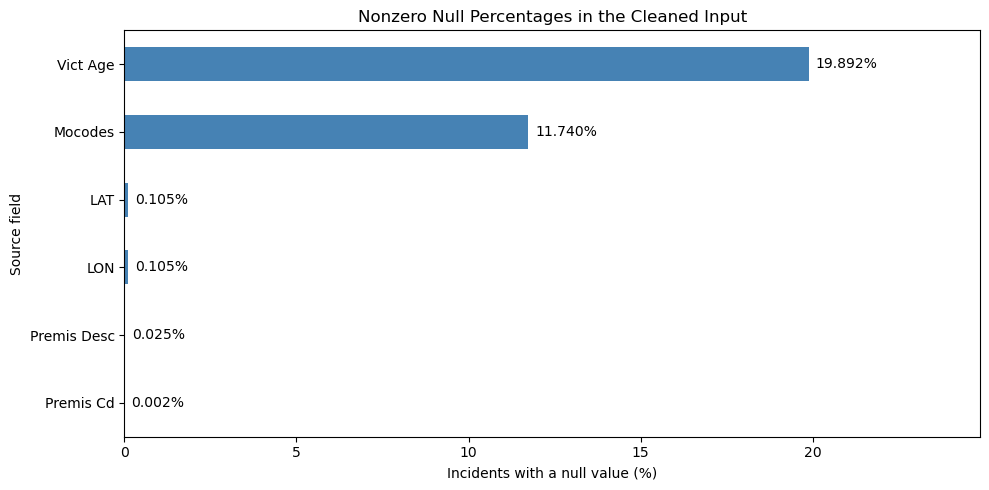

In [37]:
# plot the columns with missing values before filling ages
missing_plot = missing_pct[missing_pct > 0].sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
missing_plot.plot(kind='barh', ax=ax, color='steelblue')
for i, value in enumerate(missing_plot):
    ax.text(value + 0.2, i, f'{value:.3f}%', va='center')
ax.set_title('Nonzero Null Percentages in the Cleaned Input')
ax.set_xlabel('Incidents with a null value (%)')
ax.set_ylabel('Source field')
ax.set_xlim(0, missing_plot.max() * 1.25)
plt.tight_layout()
plt.savefig('../images/features_missingness.png', dpi=150)
plt.show()

### 2. Grouping hours into parts of the day

I group hours into Night (00-05), Morning (06-11), Afternoon (12-17) and Evening (18-23). The first chart keeps the detail; the second shows the simpler groups used for modeling. Some recorded times may be rounded or approximate.

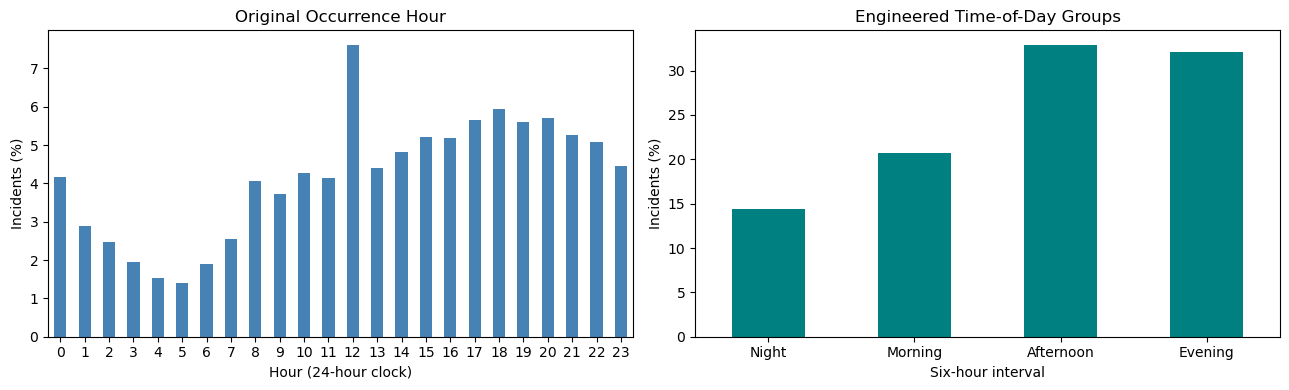

In [38]:
# compare individual hours with the four time-of-day groups
hour_pct = df['hour'].value_counts(normalize=True).sort_index() * 100
bin_pct = df['hour_bin'].value_counts(normalize=True).reindex(hour_labels) * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hour_pct.plot(kind='bar', ax=ax[0], color='steelblue', rot=0)
bin_pct.plot(kind='bar', ax=ax[1], color='teal', rot=0)
ax[0].set_title('Original Occurrence Hour')
ax[1].set_title('Engineered Time-of-Day Groups')
ax[0].set_xlabel('Hour (24-hour clock)')
ax[1].set_xlabel('Six-hour interval')
for axis in ax:
    axis.set_ylabel('Incidents (%)')
plt.tight_layout()
plt.savefig('../images/features_time_groups.png', dpi=150)
plt.show()


### 3. Using fewer categories

Crime codes, premise descriptions and weapon descriptions are combined into broader groups before encoding. This keeps the number of input columns manageable, but loses some detail. The source counts exclude missing values; the new groups include fallback labels such as `Other`.

In [39]:
# count categories before and after grouping
source_cols = ['Crm Cd', 'Premis Desc', 'Weapon Desc']
group_cols = ['Crime Category', 'Premise Group', 'Weapon Group']
group_sizes = pd.DataFrame({
    'Source values': df[source_cols].nunique().to_numpy(),
    'Engineered groups': df[group_cols].nunique().to_numpy()
}, index=['Crime', 'Premise', 'Weapon'])
group_sizes


,Source values,Engineered groups
Crime,143,9
Premise,319,13
Weapon,80,5


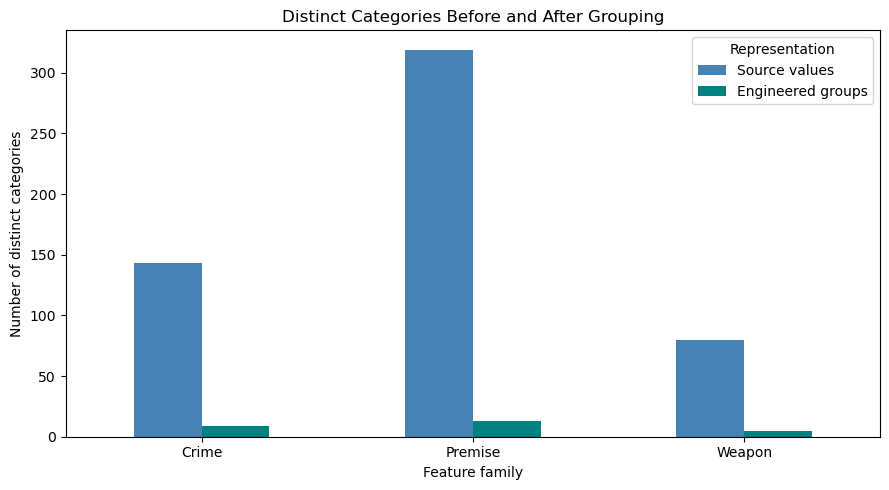

In [40]:
# plot how grouping reduces the number of categories
fig, ax = plt.subplots(figsize=(9, 5))
group_sizes.plot(kind='bar', ax=ax, color=['steelblue', 'teal'], rot=0)
ax.set_title('Distinct Categories Before and After Grouping')
ax.set_xlabel('Feature family')
ax.set_ylabel('Number of distinct categories')
ax.legend(title='Representation')
plt.tight_layout()
plt.savefig('../images/features_category_reduction.png', dpi=150)
plt.show()


### 4. Filling missing ages

The two histograms use the same intervals and record counts. Missing ages receive the median age from training records only. The tall bar shows how this changes the distribution; it does not mean those ages were actually observed. `Age Known` keeps track of which ages were originally available.

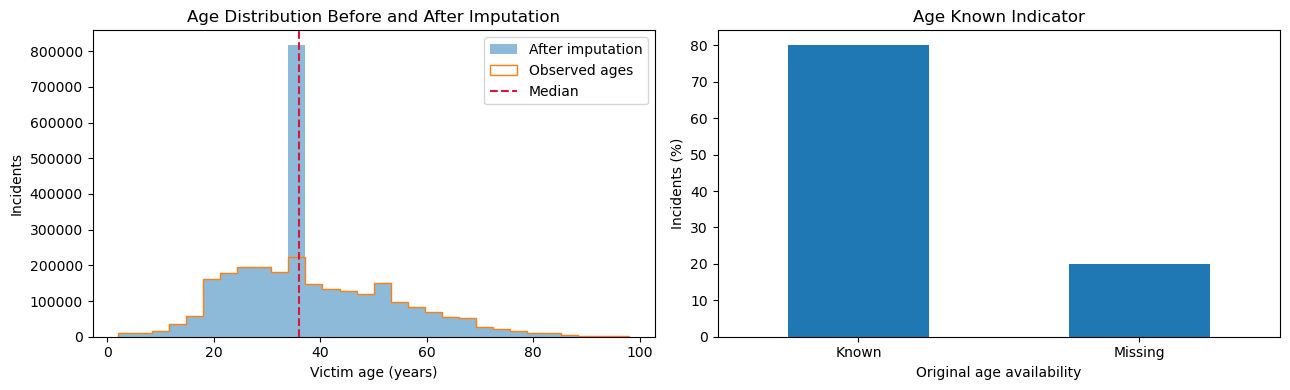

In [41]:
# compare ages before and after filling missing values
age_bins = np.linspace(df['Vict Age'].min(), df['Vict Age'].max(), 31)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df['Vict Age'], bins=age_bins, alpha=0.5, label='After imputation')
ax[0].hist(age_before.dropna(), bins=age_bins, histtype='step', label='Observed ages')
ax[0].axvline(age_median, color='crimson', linestyle='--', label='Median')
ax[0].set_title('Age Distribution Before and After Imputation')
ax[0].set_xlabel('Victim age (years)')
ax[0].set_ylabel('Incidents')
ax[0].legend()
age_status = df['Age Known'].map({0: 'Missing', 1: 'Known'})
(age_status.value_counts(normalize=True) * 100).plot(kind='bar', ax=ax[1], rot=0)
ax[1].set_title('Age Known Indicator')
ax[1].set_xlabel('Original age availability')
ax[1].set_ylabel('Incidents (%)')
plt.tight_layout()
plt.savefig('../images/features_age_imputation.png', dpi=150)
plt.show()


### 5. Looking at reporting delay on two scales

Both charts use the same records. The first shows days directly. The second uses log(1 + days), which makes the long tail easier to see. This is only a different view: no log feature is added, and reporting delay is not included in the saved predictors.

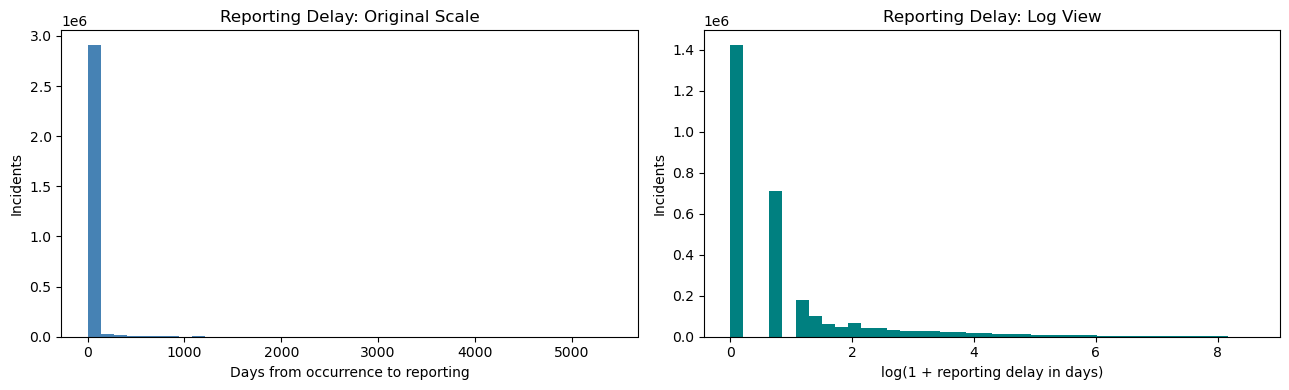

In [42]:
# show reporting delays on the original and log scales
delay = df['report_delay_days'].dropna()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(delay, bins=40, color='steelblue')
ax[1].hist(np.log1p(delay), bins=40, color='teal')
ax[0].set_title('Reporting Delay: Original Scale')
ax[1].set_title('Reporting Delay: Log View')
ax[0].set_xlabel('Days from occurrence to reporting')
ax[1].set_xlabel('log(1 + reporting delay in days)')
for axis in ax:
    axis.set_ylabel('Incidents')
plt.tight_layout()
plt.savefig('../images/features_reporting_delay.png', dpi=150)
plt.show()


### 6. Seeing one-hot encoding

The heatmap shows a repeatable sample of the four time-of-day indicator columns. A valid time group has one 1 and three 0s in its row. This small sample explains the encoding; it is not intended to show how common each time group is.

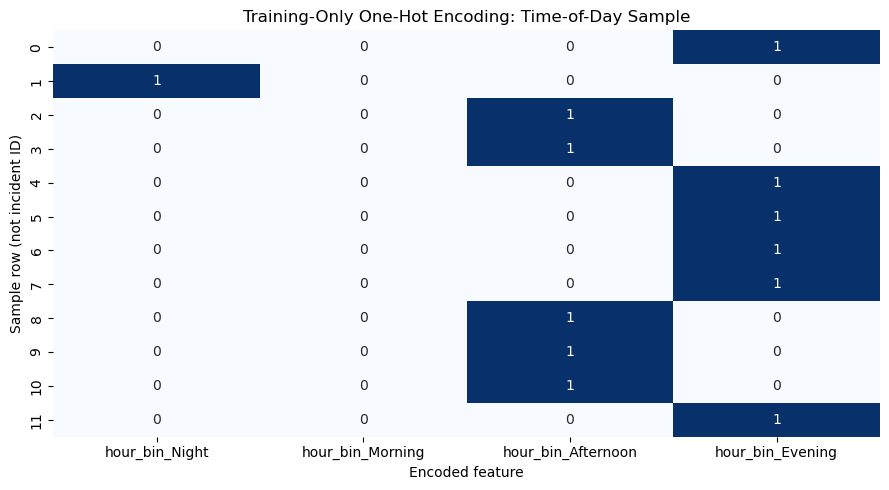

In [43]:
# show a small sample of the time-of-day indicator columns
hour_cols = ['hour_bin_' + label for label in hour_labels]
encoded_sample = X_train[hour_cols].sample(n=12, random_state=42)
encoded_sample = encoded_sample.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(encoded_sample, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
ax.set_title('Training-Only One-Hot Encoding: Time-of-Day Sample')
ax.set_xlabel('Encoded feature')
ax.set_ylabel('Sample row (not incident ID)')
plt.tight_layout()
plt.savefig('../images/features_one_hot_encoding.png', dpi=150)
plt.show()

### 7. Checking the training and test periods

Training ends in 2019; testing begins in 2020. The first chart shows the record counts by year. The second compares percentages because the two groups have different sizes. The 2024 count covers only part of the year. Neither chart measures model performance.

In [44]:
# prepare yearly counts and arrest proportions for both periods
year_counts = pd.DataFrame({
    'Train': train_df['year'].value_counts(),
    'Test': test_df['year'].value_counts()
}).fillna(0).sort_index()
balance_pct = pd.DataFrame({
    'Train': y_train.value_counts(normalize=True),
    'Test': y_test.value_counts(normalize=True)
}).reindex([0, 1]).fillna(0) * 100
balance_pct.index = ['No arrest', 'Arrest']


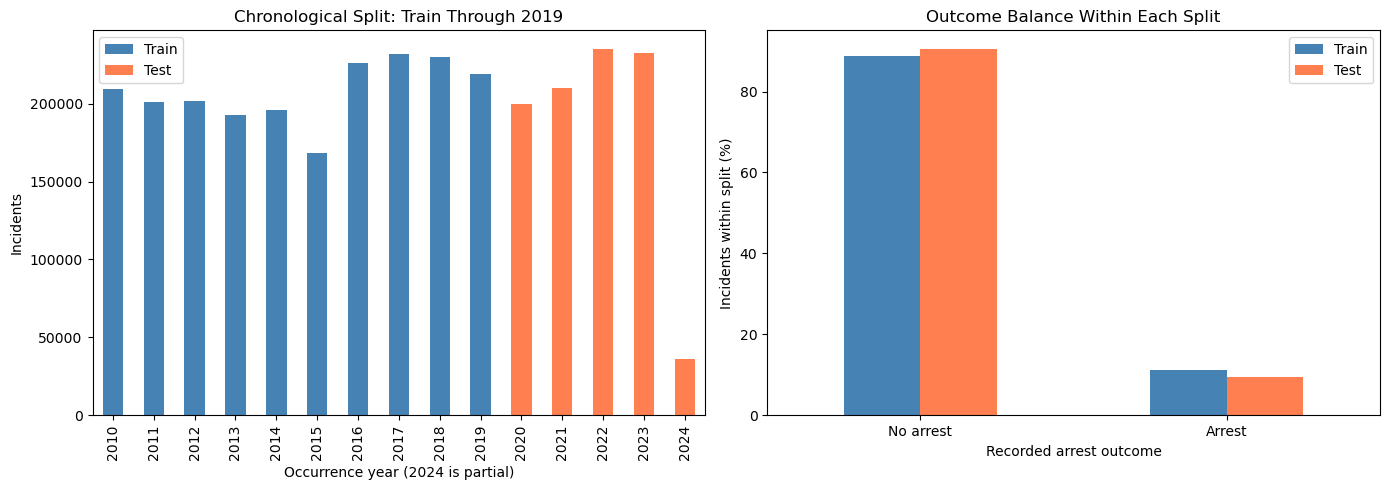

In [45]:
# plot the time split and compare arrest proportions
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
year_counts.plot(kind='bar', stacked=True, ax=ax[0], color=['steelblue', 'coral'])
balance_pct.plot(kind='bar', ax=ax[1], color=['steelblue', 'coral'], rot=0)
ax[0].set_title('Chronological Split: Train Through 2019')
ax[0].set_xlabel('Occurrence year (2024 is partial)')
ax[0].set_ylabel('Incidents')
ax[1].set_title('Outcome Balance Within Each Split')
ax[1].set_xlabel('Recorded arrest outcome')
ax[1].set_ylabel('Incidents within split (%)')
plt.tight_layout()
plt.savefig('../images/features_chronological_split.png', dpi=150)
plt.show()


### 8. Comparing crime groups over time

The bars show each crime group's percentage within its own period. Differences show that the mix of recorded crimes changes over time. They do not explain why it changes.

The age median, premise list and training indicator columns were chosen without using test records. Later model tuning will need a separate validation period within the training years. The held-out test results should not be used to choose settings.

In [46]:
# calculate crime-category percentages within each period
train_categories = df.loc[df['year'] <= split_year, 'Crime Category']
test_categories = df.loc[df['year'] >= 2020, 'Crime Category']
category_pct = pd.DataFrame({
    'Train': train_categories.value_counts(normalize=True),
    'Test': test_categories.value_counts(normalize=True)
}).fillna(0) * 100
category_pct = category_pct.sort_values(by='Train')


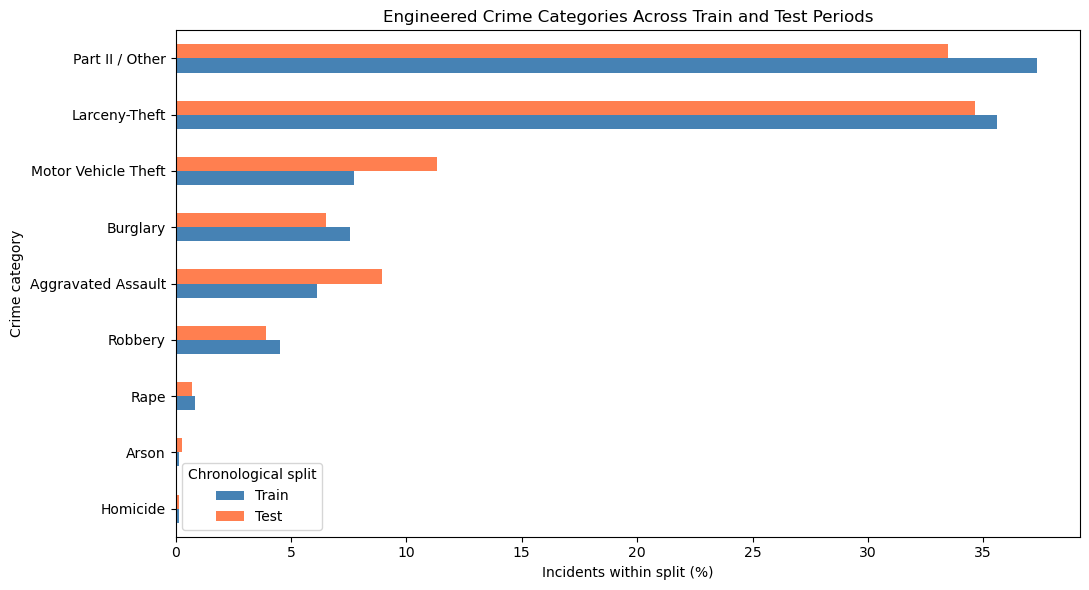

In [47]:
# compare the crime-category mix in training and test data
fig, ax = plt.subplots(figsize=(11, 6))
category_pct.plot(kind='barh', ax=ax, color=['steelblue', 'coral'])
ax.set_title('Engineered Crime Categories Across Train and Test Periods')
ax.set_xlabel('Incidents within split (%)')
ax.set_ylabel('Crime category')
ax.legend(title='Chronological split')
plt.tight_layout()
plt.savefig('../images/features_train_test_mix.png', dpi=150)
plt.show()
